# Gebarenherkenning — modelresultaten analyseren

**Model:** MediaPipe Holistic + LSTM  
**Klassen:** `idle`, `poes`, `slapen`, `vogel`

Dit notebook laadt jullie bestaande `output_models/simple_model.h5` en de `.npy`-opnames uit `mp_data`. Het maakt grafieken om te onderzoeken waarom `poes` en `slapen` soms als `vogel` worden voorspeld.

> **Belangrijk:** de oorspronkelijke trainingscode bewaart de train/test-split niet. Deze evaluatie gebruikt daarom de beschikbare opgeslagen opnames (mogelijk inclusief trainingsdata). De scores zijn **diagnostisch** en mogen niet als onafhankelijke testaccuracy worden gerapporteerd.

## 1. Imports en projectpad
Start Jupyter vanuit de hoofdmap van het project, of pas `PROJECT_ROOT` hieronder aan.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from tensorflow.keras.models import load_model

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "mp_data").exists():
    if (PROJECT_ROOT.parent / "mp_data").exists():
        PROJECT_ROOT = PROJECT_ROOT.parent
    else:
        raise FileNotFoundError("Kan mp_data niet vinden. Pas PROJECT_ROOT aan.")

DATA_PATH = PROJECT_ROOT / "mp_data"
MODEL_PATH = PROJECT_ROOT / "output_models" / "simple_model.h5"
print("Project:", PROJECT_ROOT)
print("Model aanwezig:", MODEL_PATH.is_file())

Project: /Users/youssraakdimi/Documents/GitHub/sign-language-alphabet-recognition
Model aanwezig: True


## 2. Opnames inladen en controleren
Elke opname moet uit **30 frames** bestaan, met **1659 features per frame**. Onvolledige opnames worden vermeld en overgeslagen.

In [2]:
actions = sorted(p.name for p in DATA_PATH.iterdir()
                 if p.is_dir() and not p.name.startswith("_"))
X, y_true, sequence_names, skipped = [], [], [], []

for label, action in enumerate(actions):
    for seq_dir in sorted((DATA_PATH / action).iterdir()):
        if not seq_dir.is_dir():
            continue
        frame_files = sorted(seq_dir.glob("*.npy"))
        try:
            frames = np.asarray([np.load(f) for f in frame_files], dtype=np.float32)
            if frames.shape != (30, 1659) or not np.isfinite(frames).all():
                skipped.append((action, seq_dir.name, str(frames.shape)))
                continue
            X.append(frames)
            y_true.append(label)
            sequence_names.append(f"{action}/{seq_dir.name}")
        except Exception as exc:
            skipped.append((action, seq_dir.name, str(exc)))

if not X:
    raise ValueError("Geen geldige opnames gevonden in mp_data.")
X = np.stack(X)
y_true = np.asarray(y_true)
print(f"{len(X)} geldige opnames | vorm: {X.shape} | klassen: {actions}")
print(f"{len(skipped)} overgeslagen opnames")
if skipped:
    display(pd.DataFrame(skipped, columns=["Klasse", "Opname", "Reden"]).head(20))

120 geldige opnames | vorm: (120, 30, 1659) | klassen: ['idle', 'poes', 'slapen', 'vogel']
0 overgeslagen opnames


## 3. Verdeling van de trainingsopnames

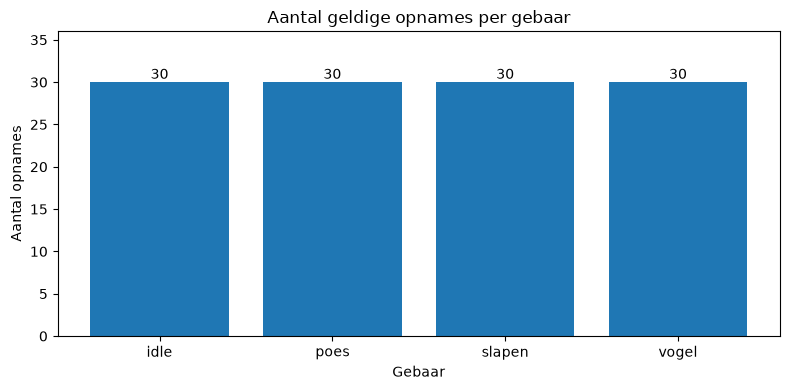

In [3]:
counts = pd.Series(y_true).map(dict(enumerate(actions))).value_counts().reindex(actions, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values)
ax.bar_label(bars)
ax.set(title="Aantal geldige opnames per gebaar", xlabel="Gebaar", ylabel="Aantal opnames")
ax.set_ylim(0, max(counts.max() * 1.2, 1))
plt.tight_layout()
plt.show()

## 4. Modelvoorspellingen berekenen
De klassevolgorde moet gelijk zijn aan de volgorde tijdens de training: alfabetisch gesorteerde mapnamen.

In [4]:
model = load_model(MODEL_PATH, compile=False)
print("Input model:", model.input_shape, "| Output model:", model.output_shape)
if model.input_shape[1:] != X.shape[1:]:
    raise ValueError(f"Verkeerde inputvorm: model {model.input_shape}, data {X.shape}")
if model.output_shape[-1] != len(actions):
    raise ValueError("Aantal modelklassen verschilt van aantal mappen in mp_data")

probabilities = model.predict(X, batch_size=16, verbose=0)
y_pred = np.argmax(probabilities, axis=1)
confidence = np.max(probabilities, axis=1)
results = pd.DataFrame({
    "opname": sequence_names,
    "werkelijk": [actions[i] for i in y_true],
    "voorspeld": [actions[i] for i in y_pred],
    "confidence": confidence,
    "correct": y_true == y_pred,
})
for i, action in enumerate(actions):
    results[f"kans_{action}"] = probabilities[:, i]
print(f"Accuracy op beschikbare opnames (NIET onafhankelijke testset): {accuracy_score(y_true, y_pred):.1%}")
display(results.head())

Input model: (None, 30, 1659) | Output model: (None, 4)
Accuracy op beschikbare opnames (NIET onafhankelijke testset): 99.2%


,opname,werkelijk,voorspeld,confidence,correct,kans_idle,kans_poes,kans_slapen,kans_vogel
0,idle/000,idle,idle,0.999882,True,0.999882,0.000024,0.000041,0.000053
1,idle/001,idle,idle,0.999931,True,0.999931,0.000010,0.000043,0.000017
2,idle/002,idle,idle,0.999928,True,0.999928,0.000010,0.000046,0.000016
3,idle/003,idle,idle,0.999932,True,0.999932,0.000009,0.000042,0.000016
4,idle/004,idle,idle,0.999932,True,0.999932,0.000010,0.000042,0.000016


## 5. Confusion matrix
**Rijen = werkelijk gebaar**, **kolommen = voorspelling**. Bekijk vooral de cellen `poes → vogel` en `slapen → vogel`.

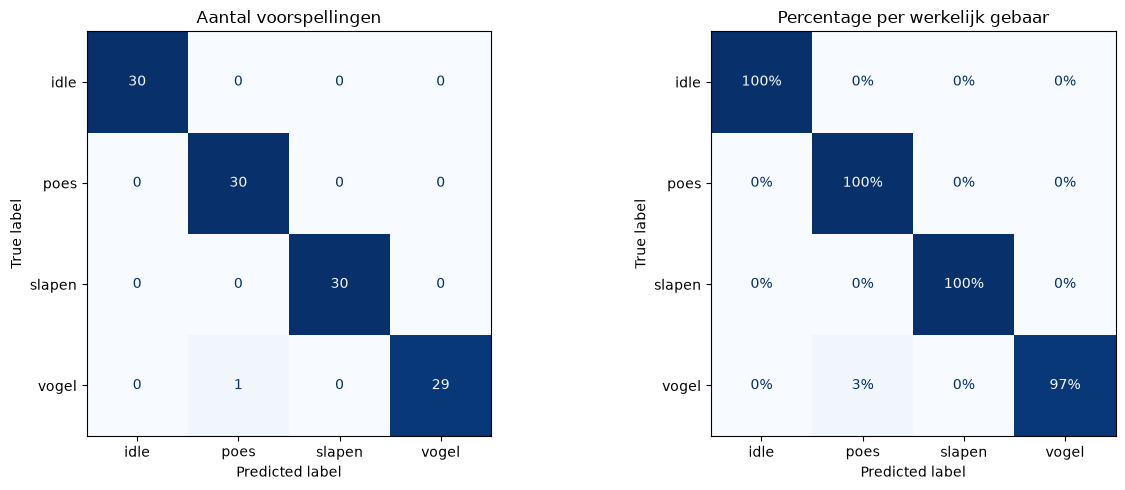

In [5]:
cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(actions)))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=actions).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Aantal voorspellingen")
cm_pct = np.divide(cm, cm.sum(axis=1, keepdims=True), out=np.zeros_like(cm, dtype=float), where=cm.sum(axis=1, keepdims=True)!=0)
ConfusionMatrixDisplay(cm_pct, display_labels=actions).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".0%")
axes[1].set_title("Percentage per werkelijk gebaar")
plt.tight_layout()
plt.show()

## 6. Precision, recall en F1-score per gebaar
Een lage **recall** voor `poes` of `slapen` betekent dat het model veel opnames van die klasse mist.

,precision,recall,f1-score,support
idle,1.000,1.000,1.000,30.000
poes,0.968,1.000,0.984,30.000
slapen,1.000,1.000,1.000,30.000
vogel,1.000,0.967,0.983,30.000
accuracy,0.992,0.992,0.992,0.992
macro avg,0.992,0.992,0.992,120.000
weighted avg,0.992,0.992,0.992,120.000


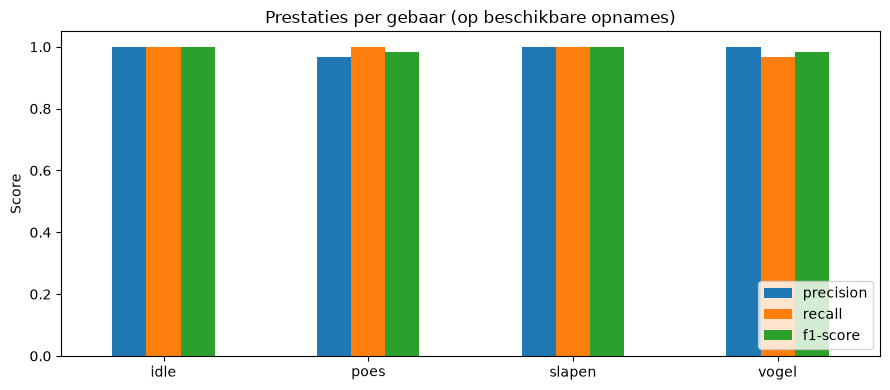

In [6]:
report = classification_report(y_true, y_pred, labels=np.arange(len(actions)),
                               target_names=actions, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
display(report_df.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
report_df.loc[actions, ["precision", "recall", "f1-score"]].plot.bar(ax=ax, rot=0)
ax.set(title="Prestaties per gebaar (op beschikbare opnames)", ylabel="Score", ylim=(0, 1.05))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 7. Welke gebaren worden als `vogel` voorspeld?

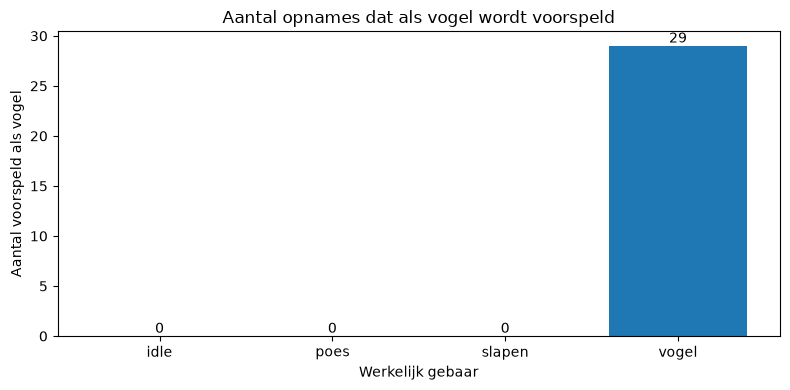

Aantal fouten: 1 van 120


,opname,werkelijk,voorspeld,confidence,correct,kans_idle,kans_poes,kans_slapen,kans_vogel
91,vogel/001,vogel,poes,100.0%,False,0.000013,0.999924,0.000011,0.000051


In [8]:
vogel_count = results.groupby("werkelijk")["voorspeld"].apply(lambda s: int((s == "vogel").sum())).reindex(actions, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(vogel_count.index, vogel_count.values)
ax.bar_label(bars)
ax.set(title="Aantal opnames dat als vogel wordt voorspeld", xlabel="Werkelijk gebaar", ylabel="Aantal voorspeld als vogel")
plt.tight_layout()
plt.show()

mistakes = results[~results["correct"]].sort_values("confidence", ascending=False)
print(f"Aantal fouten: {len(mistakes)} van {len(results)}")
mistakes_head = mistakes.head(20).copy()
mistakes_head["confidence"] = mistakes_head["confidence"].map(lambda x: f"{x:.1%}")
display(mistakes_head)

## 8. Kansverdeling per opname
De heatmap toont de kansen voor iedere klasse. Sorteer op het echte gebaar om patronen te zien.

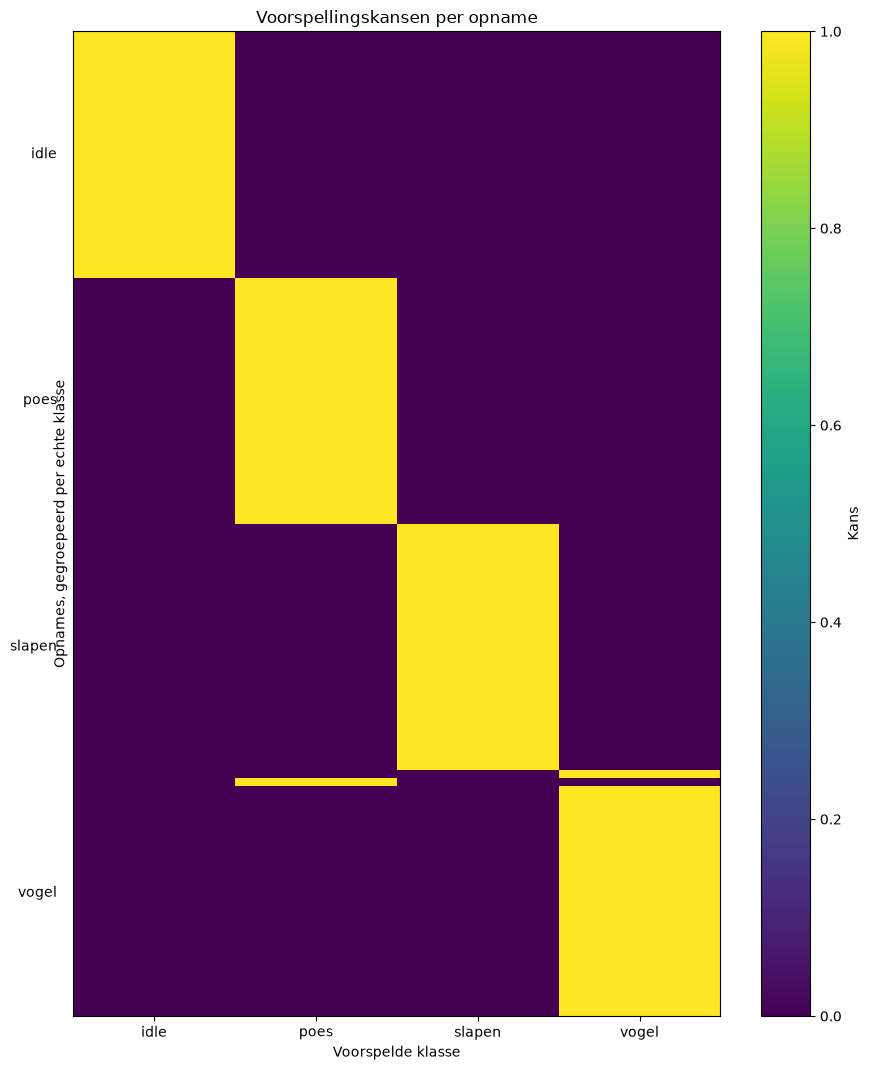

In [9]:
order = np.argsort(y_true, kind="stable")
fig, ax = plt.subplots(figsize=(9, max(5, min(15, len(X) * .09))))
im = ax.imshow(probabilities[order], aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(actions)), actions)
ax.set_yticks([])
ax.set(xlabel="Voorspelde klasse", ylabel="Opnames, gegroepeerd per echte klasse", title="Voorspellingskansen per opname")
for action in actions:
    indices = np.where(y_true[order] == actions.index(action))[0]
    if len(indices):
        ax.text(-0.6, indices.mean(), action, ha="right", va="center")
fig.colorbar(im, ax=ax, label="Kans")
plt.tight_layout()
plt.show()

## 9. Eén opname inspecteren
Pas `OPNAME` aan naar bijvoorbeeld `poes/0` of kies een naam uit de tabel hieronder.

,opname,werkelijk,voorspeld,confidence
0,idle/000,idle,idle,0.999882
1,idle/001,idle,idle,0.999931
2,idle/002,idle,idle,0.999928
3,idle/003,idle,idle,0.999932
4,idle/004,idle,idle,0.999932
5,idle/005,idle,idle,0.999928
6,idle/006,idle,idle,0.999862
7,idle/007,idle,idle,0.999862
8,idle/008,idle,idle,0.999862
9,idle/009,idle,idle,0.999862


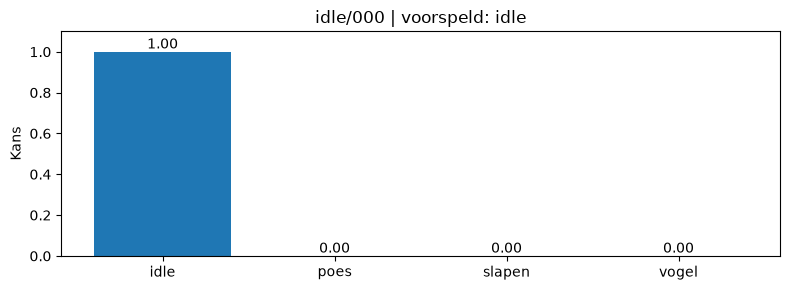

In [10]:
display(results[["opname", "werkelijk", "voorspeld", "confidence"]].head(15))
OPNAME = sequence_names[0]  # Verander naar een bestaande opname
row = results.loc[results["opname"] == OPNAME]
if row.empty:
    print("Onbekende opname:", OPNAME)
else:
    values = row[[f"kans_{a}" for a in actions]].iloc[0].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(8, 3))
    bars = ax.bar(actions, values)
    ax.bar_label(bars, fmt="%.2f")
    ax.set(ylim=(0, 1.1), ylabel="Kans", title=f"{OPNAME} | voorspeld: {row.iloc[0]['voorspeld']}")
    plt.tight_layout()
    plt.show()

## 10. Resultaten exporteren en interpreteren
De CSV bevat per opname de echte klasse, voorspelling en alle kansen. Je kunt deze later gebruiken voor het verslag.

In [ ]:
OUTPUT = PROJECT_ROOT / "model_results.csv"
results.to_csv(OUTPUT, index=False)
print("Opgeslagen:", OUTPUT)
print("Samenvatting:")
for action in actions:
    subset = results[results["werkelijk"] == action]
    if len(subset):
        print(f"- {action}: {(subset['correct']).mean():.1%} correct op beschikbare opnames ({len(subset)} opnames)")

print("LET OP: dit is een diagnostische evaluatie op opgeslagen data, niet een onafhankelijke testset.")

SyntaxError: unterminated string literal (detected at line 4) (1394089160.py, line 4)

### Wat betekenen de resultaten?

- **Ook opgeslagen `poes`/`slapen` → `vogel`?** Onderzoek labels, trainingsdata en modeltraining.
- **Opgeslagen opnames goed, maar webcam slecht?** Onderzoek camerahoek, opname-timing, achtergrond, landmarks en het verschil tussen vaste 30 frames en resampling met B/S.
- **100% confidence maar fout?** Dat is mogelijk bij overzekere neurale netwerken; confidence is geen bewijs van juistheid.

**Voor een eerlijke evaluatie:** neem een aparte, nieuwe testset op die nooit is gebruikt bij training, of pas de trainingscode aan om een vaste gestratificeerde train/validation/test-split op te slaan.